In [2]:
from google.colab import files
uploaded = files.upload()

Saving fake.csv to fake.csv
Saving true.csv to true.csv


In [3]:

import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

fake_df = pd.read_csv("/content/fake.csv")
real_df = pd.read_csv("/content/true.csv")

fake_df["label"] = 0
real_df["label"] = 1

df = pd.concat([fake_df, real_df], ignore_index=True)

df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

df["text"] = (df["title"] + " " + df["text"]).str.strip()

df = df[df["text"] != ""]
df = df.drop_duplicates(subset=["text"])

fake_sample = df[df["label"] == 0].sample(
    n=1000, random_state=42
)
real_sample = df[df["label"] == 1].sample(
    n=1000, random_state=42
)

df = pd.concat(
    [fake_sample, real_sample],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

df = df[["text", "label"]]

print("TensorFlow version:", tf.__version__)
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nMissing values:")
print(df.isnull().sum())
print("\nSample articles:")
print(df.head())


TensorFlow version: 2.21.0
Dataset shape: (2000, 2)

Class distribution:
label
1    1000
0    1000
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Sample articles:
                                                text  label
0  In Georgia, costliest U.S. House race hits ugl...      1
1  Bernie Gives Us Hope, Promises To Protect Mino...      0
2  U.S. appeals court questions scope of Trump tr...      1
3  Trump ‘Promises’ To Fix Black People’s Problem...      0
4  Countdown to Brexit breakthrough? BRUSSELS (Re...      1


In [4]:

X = df["text"]
y = df["label"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

max_len = 300

X_train = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

vocab_size = min(
    10000,
    len(tokenizer.word_index) + 1
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Vocabulary size:", vocab_size)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training samples: 1600
Testing samples: 400
Vocabulary size: 10000
Training shape: (1600, 300)
Testing shape: (400, 300)


In [6]:

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True,
        input_shape=(max_len,)
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 170ms/step - accuracy: 0.5398 - loss: 0.6802 - val_accuracy: 0.4906 - val_loss: 0.7847
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 169ms/step - accuracy: 0.8805 - loss: 0.3811 - val_accuracy: 0.9406 - val_loss: 0.2342
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 190ms/step - accuracy: 0.9383 - loss: 0.2392 - val_accuracy: 0.9000 - val_loss: 0.2890
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 163ms/step - accuracy: 0.9391 - loss: 0.2048 - val_accuracy: 0.9062 - val_loss: 0.2706
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 163ms/step - accuracy: 0.9477 - loss: 0.1704 - val_accuracy: 0.9062 - val_loss: 0.2913
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step - accuracy: 0.9492 - loss: 0.1423 - val_accuracy: 0.9031 - val_loss: 0.3210
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 204ms/step - accuracy: 0.9680 - loss: 0.0951 - val_accuracy: 0.9438 - val_loss: 0.1941
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 166ms/step - accuracy: 0.9797 - loss: 0.0600 - val_accurac

In [8]:

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"],
    zero_division=0
))


Accuracy: 0.675
Precision: 0.6080246913580247
Recall: 0.985
F1-score: 0.7519083969465649

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.96      0.36      0.53       200
   Real News       0.61      0.98      0.75       200

    accuracy                           0.68       400
   macro avg       0.78      0.68      0.64       400
weighted avg       0.78      0.68      0.64       400



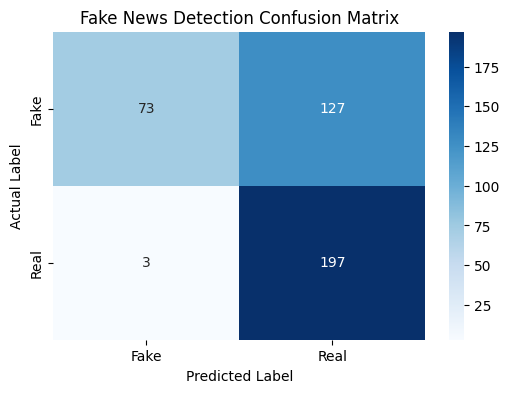

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fake News Detection Confusion Matrix")
plt.show()


In [11]:

news = [
    "The government announced a new policy after a meeting "
    "with officials, according to a news report."
]

news_seq = tokenizer.texts_to_sequences(news)

news_pad = pad_sequences(
    news_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

probability = float(model.predict(news_pad, verbose=0)[0][0])

print("Probability of real news:", round(probability, 4))

if probability >= 0.5:
    print("Prediction: Real News")
else:
    print("Prediction: Fake News")


Probability of real news: 0.6604
Prediction: Real News
